In [1]:
# === CELDA 1: Setup (sin dependencias nuevas: cv2 + numpy, que ya tienes) ===
import cv2, numpy as np, random, shutil
from pathlib import Path
from collections import Counter
from tqdm import tqdm

print("cv2:", cv2.__version__, "| numpy:", np.__version__)
SEED = 0
random.seed(SEED); np.random.seed(SEED)

cv2: 4.13.0 | numpy: 2.4.5


In [2]:
# === CELDA 2: Configuración ===
SRC = Path(r"C:\Users\sgghu\Downloads\dataset_v5")          # original (NO se toca)
DST = Path(r"C:\Users\sgghu\Downloads\dataset_v5_aug")      # salida (se crea)

CLASSES = ["ball", "player", "referee"]
BALL, PLAYER, REFEREE = 0, 1, 2

# Oversampling DIRIGIDO a las clases débiles. El árbitro es el más raro y el que
# más margen tiene -> más copias. El balón está en casi todas las imgs -> copias medias.
# Solo-jugador no se oversamplea (ya vas sobrado: mAP 0.98).
AUG_ARBITRO      = 2   # la clase más débil: 1-2 copias como mucho
AUG_BALON        = 1
AUG_SOLO_JUGADOR = 0   # jugador ya va a mAP 0.98 -> no malgastes cómputo en él

IMG_EXTS = {".jpg", ".jpeg", ".png"}

In [3]:
# === CELDA 3: pipeline de augmentation (solo fotométrico -> NO mueve las cajas) ===
# Lo geométrico ya lo hace YOLO online; esto añade lo que YOLO NO hace y que ataca
# tu dominio broadcast. Como nada mueve objetos, las cajas se copian sin tocar.

def _jpeg(img):                                  # compresión broadcast
    q = random.randint(45, 90)
    ok, enc = cv2.imencode(".jpg", img, [int(cv2.IMWRITE_JPEG_QUALITY), q])
    return cv2.imdecode(enc, cv2.IMREAD_COLOR) if ok else img

def _motion_blur(img):                           # movimiento rápido (balón/jugadores)
    k = random.choice([3, 5, 7])
    kernel = np.zeros((k, k), np.float32)
    if random.random() < 0.5: kernel[k // 2, :] = 1.0      # horizontal
    else:                     kernel[:, k // 2] = 1.0      # vertical
    kernel /= k
    return cv2.filter2D(img, -1, kernel)

def _gauss_blur(img):
    k = random.choice([3, 5])
    return cv2.GaussianBlur(img, (k, k), 0)

def _brightness_contrast(img):                   # alpha=contraste, beta=brillo
    return cv2.convertScaleAbs(img, alpha=1.0 + random.uniform(-0.2, 0.2),
                                    beta=random.uniform(-25, 25))

def _gamma(img):                                 # iluminación de estadio
    g = random.uniform(0.8, 1.2)
    lut = np.array([((i / 255.0) ** (1.0 / g)) * 255 for i in range(256)], np.uint8)
    return cv2.LUT(img, lut)

def _clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

PIPELINE = [(_jpeg, 0.5), (_brightness_contrast, 0.5), (_gamma, 0.3), (_clahe, 0.2)]

def augmentar(img):
    out = img.copy()
    if random.random() < 0.3:                    # como mucho un blur, 30% de las veces
        out = _motion_blur(out) if random.random() < 0.6 else _gauss_blur(out)
    for fn, p in PIPELINE:
        if random.random() < p:
            out = fn(out)
    return out

In [4]:
# === CELDA 4: utilidades ===
def leer_labels(label_path):
    bboxes, clases = [], []
    if not label_path.exists():
        return bboxes, clases
    for line in label_path.read_text().strip().splitlines():
        if line.strip():
            c, x, y, w, h = line.split()[:5]
            clases.append(int(c)); bboxes.append([float(x), float(y), float(w), float(h)])
    return bboxes, clases

def escribir_labels(label_path, bboxes, clases):
    label_path.write_text("\n".join(
        f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, (x, y, w, h) in zip(clases, bboxes)))

def n_copias(clases):
    s = set(clases)
    if REFEREE in s: return AUG_ARBITRO
    if BALL in s:    return AUG_BALON
    return AUG_SOLO_JUGADOR

In [7]:
# === CELDA 5: estructura de salida (valid/test intactos + originales de train) ===
if DST.exists():
    raise SystemExit(f"{DST} ya existe. Bórralo a mano si quieres regenerar (seguridad).")

for split in ["train", "valid", "test"]:
    (DST / split / "images").mkdir(parents=True, exist_ok=True)
    (DST / split / "labels").mkdir(parents=True, exist_ok=True)

# valid y test: copia EXACTA (la augmentation NUNCA los toca)
for split in ["valid", "test"]:
    si = SRC / split / "images"
    if not si.exists():
        print(f"(aviso) {si} no existe, lo salto"); continue
    for img in si.iterdir():
        if img.suffix.lower() in IMG_EXTS:
            shutil.copy2(img, DST / split / "images" / img.name)
    for lbl in (SRC / split / "labels").glob("*.txt"):
        shutil.copy2(lbl, DST / split / "labels" / lbl.name)
    print(f"{split}: copiado intacto")

# train: copiamos los ORIGINALES (la augmentation se añade encima)
train_imgs = [p for p in (SRC / "train" / "images").iterdir() if p.suffix.lower() in IMG_EXTS]
for img in train_imgs:
    shutil.copy2(img, DST / "train" / "images" / img.name)
    lbl = SRC / "train" / "labels" / (img.stem + ".txt")
    if lbl.exists():
        shutil.copy2(lbl, DST / "train" / "labels" / lbl.name)
print(f"train: {len(train_imgs)} originales copiados")

valid: copiado intacto
test: copiado intacto
train: 836 originales copiados


In [8]:
# === CELDA 6: generar augmentadas (SOLO train, cajas copiadas sin tocar) ===
generadas = fallidas = 0
for img_path in tqdm(train_imgs, desc="Augmentando train"):
    lbl_path = SRC / "train" / "labels" / (img_path.stem + ".txt")
    _, clases = leer_labels(lbl_path)
    if not clases:
        continue                                  # sin cajas no augmentamos
    image = cv2.imread(str(img_path))
    if image is None:
        fallidas += 1; continue
    for i in range(n_copias(clases)):
        stem = f"{img_path.stem}_aug{i}"
        cv2.imwrite(str(DST / "train" / "images" / f"{stem}.jpg"), augmentar(image))
        shutil.copy2(lbl_path, DST / "train" / "labels" / f"{stem}.txt")   # cajas idénticas
        generadas += 1

print(f"Augmentadas: {generadas} | fallidas: {fallidas}")
print(f"Train total: {len(train_imgs)} + {generadas} = {len(train_imgs)+generadas}")

Augmentando train: 100%|██████████| 836/836 [00:30<00:00, 27.63it/s] 

Augmentadas: 1592 | fallidas: 0
Train total: 836 + 1592 = 2428


In [9]:
# === CELDA 7: data.yaml ===
(DST / "data.yaml").write_text(
    f"path: {DST.as_posix()}\ntrain: train/images\nval: valid/images\ntest: test/images\n\n"
    f"nc: {len(CLASSES)}\nnames: {CLASSES}\n")
print((DST / "data.yaml").read_text())

path: C:/Users/sgghu/Downloads/dataset_v5_aug
train: train/images
val: valid/images
test: test/images

nc: 3
names: ['ball', 'player', 'referee']



train: 2428 imgs | { ball: 2070, player: 45533, referee: 4248 }
valid: 247 imgs | { ball: 208, player: 4550, referee: 440 }
test: 115 imgs | { ball: 103, player: 2183, referee: 249 }


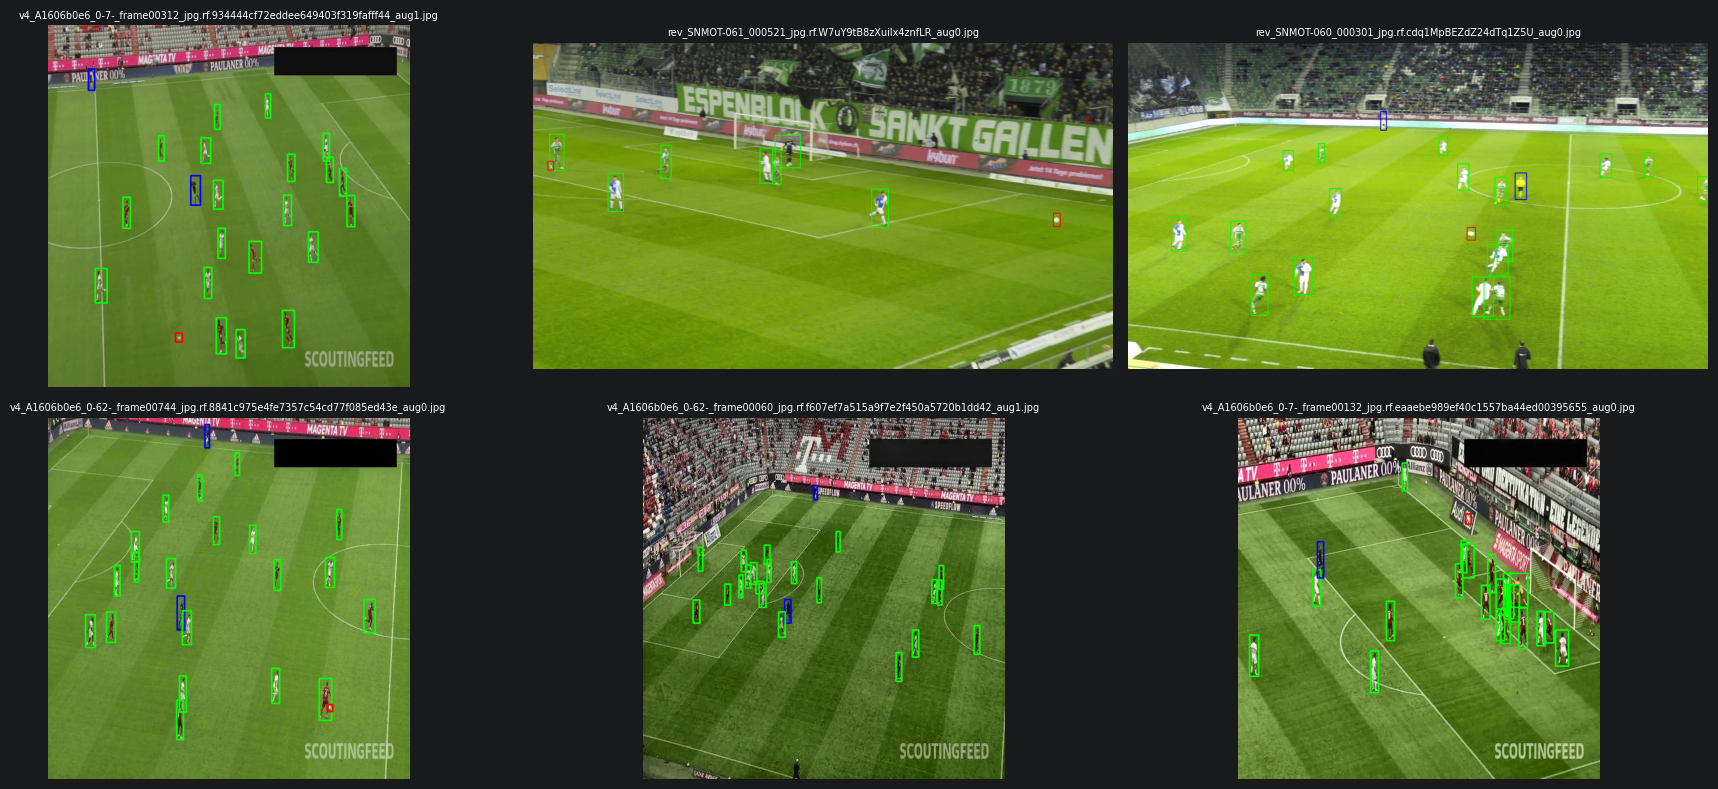

In [10]:
# === CELDA 8: verificación (conteo de clases + SANITY CHECK visual de cajas) ===
import matplotlib.pyplot as plt

def contar(split):
    cnt, n = Counter(), 0
    for lbl in (DST / split / "labels").glob("*.txt"):
        n += 1
        for line in lbl.read_text().strip().splitlines():
            if line.strip(): cnt[int(line.split()[0])] += 1
    return n, cnt

for split in ["train", "valid", "test"]:
    n, cnt = contar(split)
    print(f"{split}: {n} imgs | {{ {', '.join(f'{CLASSES[c]}: {cnt.get(c,0)}' for c in range(3))} }}")

# Dibuja cajas sobre 6 augmentadas al azar -> verifica que las bboxes siguen bien puestas
aug_files = list((DST / "train" / "images").glob("*_aug*.jpg"))
COLORS = {0:(0,0,255), 1:(0,255,0), 2:(255,0,0)}   # ball=rojo, player=verde, ref=azul (BGR)
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, f in zip(axes.ravel(), random.sample(aug_files, min(6, len(aug_files)))):
    im = cv2.imread(str(f)); H, W = im.shape[:2]
    bb, cl = leer_labels(DST / "train" / "labels" / (f.stem + ".txt"))
    for (x, y, w, h), c in zip(bb, cl):
        cv2.rectangle(im, (int((x-w/2)*W), int((y-h/2)*H)),
                          (int((x+w/2)*W), int((y+h/2)*H)), COLORS.get(c,(255,255,255)), 2)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(f.name, fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

In [11]:
# === CELDA 9: entrenar v5-aug (mismo config que el baseline salvo batch) ===
from ultralytics import YOLO
YOLO("yolov8s.pt").train(
    data=r"C:\Users\sgghu\Downloads\dataset_v5_aug\data.yaml",
    epochs=50, imgsz=1280, batch=4, device=0, patience=15,
    workers=0, cache=False, amp=True,
    project=r"C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\runs\detect\models",
    name="detector_v5_aug_1280",
)

New https://pypi.org/project/ultralytics/8.4.71 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\sgghu\Downloads\dataset_v5_aug\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001B00D684520>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          

In [12]:
# === Copiar el mejor checkpoint de v5 a models/ ===
import shutil
from pathlib import Path
src = Path(r"C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\runs\detect\models\detector_v5_1280\weights\best.pt")
dst = Path(r"C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\models\best_v5.pt")
dst.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(src, dst)
print("Copiado:", dst, f"({dst.stat().st_size/1e6:.1f} MB)")

Copiado: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\models\best_v5.pt (22.7 MB)


In [13]:
# === Comparación v4 vs v5 sobre el mismo test (por clase) ===
from ultralytics import YOLO

# MISMO test que ya usas en el notebook 07 para v1-v4 (74 frames DFL held-out).
DATA_YAML = r"C:\Users\sgghu\Downloads\dataset_v4_v2\data.yaml"   # <-- ajusta al que uses en el 07
SPLIT, IMGSZ = "test", 1280

MODELOS = {"v4": r"C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\models\best_v4.pt",
           "v5": r"C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\models\best_v5.pt"}

res = {}
for nombre, ruta in MODELOS.items():
    print(f"\n=== Evaluando {nombre} ===")
    m = YOLO(ruta)
    met = m.val(data=DATA_YAML, split=SPLIT, imgsz=IMGSZ,
                conf=0.001, iou=0.7, verbose=False, plots=False)
    por_clase = {}
    for idx in met.box.ap_class_index:
        idx = int(idx)
        pos = list(met.box.ap_class_index).index(idx)
        p, r, ap50, ap = met.box.class_result(pos)
        por_clase[m.names[idx]] = (p, r, ap50, ap)
    res[nombre] = {"global": (met.box.mp, met.box.mr, met.box.map50, met.box.map),
                   "clases": por_clase}

def tabla(metrica, col):
    titulo = "mAP50" if metrica == 2 else "mAP50-95"
    print("\n" + "="*60)
    print(f"{'':10}{'v4 '+titulo:>14}{'v5 '+titulo:>14}{'Δ':>10}")
    print("-"*60)
    for c in ["ball", "player", "referee"]:
        a = res["v4"]["clases"].get(c,(0,0,0,0))[metrica]
        b = res["v5"]["clases"].get(c,(0,0,0,0))[metrica]
        print(f"{c:10}{a:>14.3f}{b:>14.3f}{b-a:>+10.3f}")
    a, b = res["v4"]["global"][col], res["v5"]["global"][col]
    print("-"*60); print(f"{'all':10}{a:>14.3f}{b:>14.3f}{b-a:>+10.3f}")

tabla(2, 2)   # mAP50 por clase
tabla(3, 3)   # mAP50-95 por clase


=== Evaluando v4 ===
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
Model summary (fused): 73 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 116.026.2 MB/s, size: 70.6 KB)
val: Scanning C:\Users\sgghu\Downloads\dataset_v4_v2\test\labels... 74 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 74/74 856.6it/s 0.1s
val: New cache created: C:\Users\sgghu\Downloads\dataset_v4_v2\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7s/it 8.3s1.4sss
                   all         74       1782      0.771      0.678      0.706      0.385
Speed: 16.4ms preprocess, 79.0ms inference, 0.0ms loss, 4.9ms postprocess per image

=== Evaluando v5 ===
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
Model summary (fused): 73 layers, 11,126,745 parameters, 0 gradients, 28.4 G